In [55]:
import random
import pandas as pd
import matplotlib.pyplot as plt

In [83]:
dataset_path = "./dataset/melb_data.csv"
melb_data = pd.read_csv(dataset_path)

In [84]:
melb_data.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


## Make one feature dataset
we are going to make a dataset with just one feature.    
Here we are going to use `Landsize` as our feature and `Price` as label.    
In this dataset we have noise, null and zero values.    
In this project for simplicity we will remove those values that have under `40` Landsize and na values.    
Also we will select around 5000 of these for linear regression model

In [85]:
melb_data = melb_data.dropna(axis=0)
one_feature_dataset = melb_data[["Landsize", "Price"]]
zero_landsize = one_feature_dataset["Landsize"] >= 40
one_feature_dataset = one_feature_dataset.loc[zero_landsize]
one_feature_dataset[:5]

,Landsize,Price
1,156.0,1035000.0
2,134.0,1465000.0
4,120.0,1600000.0
6,245.0,1876000.0
7,256.0,1636000.0


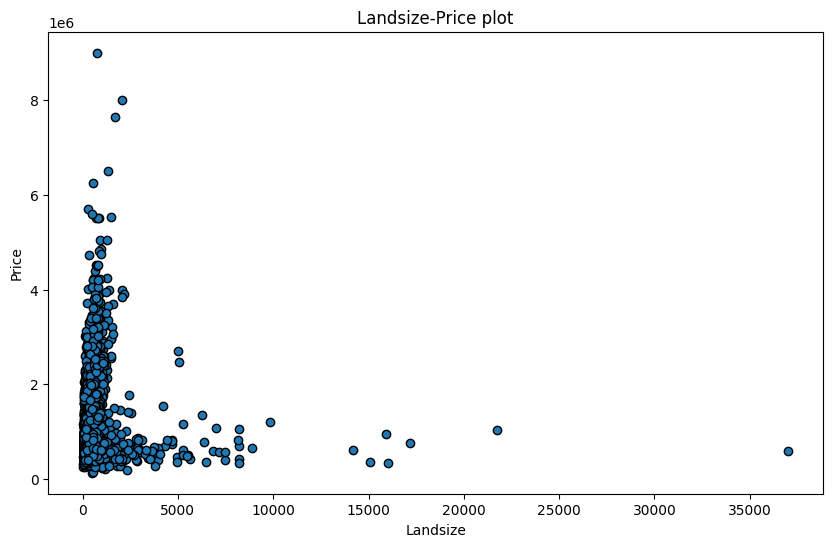

In [87]:
plt.figure(figsize=(10, 6))
plt.title("Landsize-Price plot")
plt.xlabel("Landsize")
plt.ylabel("Price")
plt.scatter(
    x = one_feature_dataset["Landsize"], 
    y = one_feature_dataset["Price"],
    edgecolors="Black"
    )
plt.show()

In [88]:
one_feature_dataset.describe()

,Landsize,Price
count,5176.000000,5.176000e+03
mean,563.807960,1.156602e+06
std,954.903415,6.916140e+05
min,43.000000,1.310000e+05
25%,248.000000,7.000000e+05
50%,488.500000,9.600000e+05
75%,660.000000,1.417312e+06
max,37000.000000,9.000000e+06


## Linear Regression model
Now In this part we are going to build an object of linear regression from `linear_regression.py` code. 